In [35]:
from datetime import datetime, timedelta

In [36]:
start = "2010-01-01"
end = "2026-01-01"

In [37]:
from weather_anamoly.lstm import lstm_multivariate_feature_generation

In [38]:
from weather_anamoly.utils import ImportCoordinates, ImportData

In [39]:
coor = ImportCoordinates()
lat, long = coor.Fetch_coordinates("machilipatnam")
data = ImportData()

In [40]:
df = data.extract(start_date=start, end_date=end, latitude=lat, longitude=long)

In [41]:
df

,date,temperature,humidity,pressure
0,2009-12-31 18:30:00+00:00,22.487000,89.573792,1011.781250
1,2009-12-31 19:30:00+00:00,23.487000,85.357048,1011.783997
2,2009-12-31 20:30:00+00:00,23.136999,87.180107,1010.983704
3,2009-12-31 21:30:00+00:00,21.386999,93.168587,1010.679260
4,2009-12-31 22:30:00+00:00,20.386999,95.760002,1011.175964
...,...,...,...,...
140275,2026-01-01 13:30:00+00:00,23.799999,83.572594,1011.884949
140276,2026-01-01 14:30:00+00:00,23.500000,83.024963,1012.783203
140277,2026-01-01 15:30:00+00:00,23.200001,83.246887,1012.982483
140278,2026-01-01 16:30:00+00:00,23.100000,84.270790,1013.181946


In [42]:
df_ = lstm_multivariate_feature_generation(df=df)

In [43]:
df_

,date,temperature,humidity,pressure,hour,month,temperature_mean,temperature_std,pressure_mean,pressure_std,humidity_mean,humidity_std,z_temperature,z_humidity,z_pressure
0,2009-12-31 18:30:00+00:00,22.487000,89.573792,1011.781250,18,12,22.627899,1.474379,1012.623651,2.201972,85.900960,6.622353,-0.095565,0.554611,-0.382567
1,2009-12-31 19:30:00+00:00,23.487000,85.357048,1011.783997,19,12,22.261702,1.567079,1012.113792,2.204977,87.263003,6.460913,0.781899,-0.294998,-0.149569
2,2009-12-31 20:30:00+00:00,23.136999,87.180107,1010.983704,20,12,21.910897,1.662868,1011.596932,2.214623,88.454159,6.581974,0.737342,-0.193567,-0.276900
3,2009-12-31 21:30:00+00:00,21.386999,93.168587,1010.679260,21,12,21.613714,1.770185,1011.432455,2.223610,89.373583,6.689235,-0.128074,0.567330,-0.338726
4,2009-12-31 22:30:00+00:00,20.386999,95.760002,1011.175964,22,12,21.379408,1.840198,1011.493929,2.221873,89.986967,6.751983,-0.539295,0.855013,-0.143107
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
140275,2026-01-01 13:30:00+00:00,23.799999,83.572594,1011.884949,13,1,24.161929,0.818693,1012.939103,1.869288,76.694523,6.081464,-0.442083,1.130989,-0.563934
140276,2026-01-01 14:30:00+00:00,23.500000,83.024963,1012.783203,14,1,23.728529,0.894890,1013.628306,1.861637,79.121125,6.260155,-0.255371,0.623601,-0.453957
140277,2026-01-01 15:30:00+00:00,23.200001,83.246887,1012.982483,15,1,23.317261,1.005462,1014.021826,1.857600,81.274135,6.387811,-0.116624,0.308831,-0.559509
140278,2026-01-01 16:30:00+00:00,23.100000,84.270790,1013.181946,16,1,22.917966,1.088227,1014.080435,1.862286,83.287319,6.395492,0.167276,0.153776,-0.482466


In [44]:
df_.columns

Index(['date', 'temperature', 'humidity', 'pressure', 'hour', 'month',
       'temperature_mean', 'temperature_std', 'pressure_mean', 'pressure_std',
       'humidity_mean', 'humidity_std', 'z_temperature', 'z_humidity',
       'z_pressure'],
      dtype='str')

In [45]:
features = ["z_temperature", "z_humidity", "z_pressure"]

In [46]:
df_[features]

,z_temperature,z_humidity,z_pressure
0,-0.095565,0.554611,-0.382567
1,0.781899,-0.294998,-0.149569
2,0.737342,-0.193567,-0.276900
3,-0.128074,0.567330,-0.338726
4,-0.539295,0.855013,-0.143107
...,...,...,...
140275,-0.442083,1.130989,-0.563934
140276,-0.255371,0.623601,-0.453957
140277,-0.116624,0.308831,-0.559509
140278,0.167276,0.153776,-0.482466


In [47]:
df_train = df_
df_train.reset_index(drop=True, inplace=True)

In [48]:
import seaborn as sns
import matplotlib.pyplot as plt

<Axes: xlabel='None', ylabel='z_temperature'>

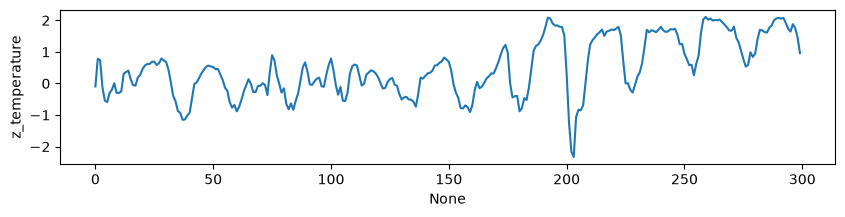

In [49]:
plt.figure(figsize=(10,2))
sns.lineplot(data=df_train.iloc[:300],x=df_train.index[:300], y='z_temperature')

<Axes: xlabel='None', ylabel='temperature'>

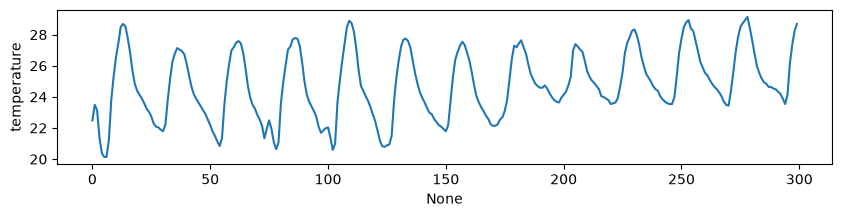

In [50]:
plt.figure(figsize=(10,2))
sns.lineplot(data=df_.iloc[:300], x=df_.index[:300], y='temperature')

In [51]:
import numpy as np

In [52]:
from weather_anamoly.lstm import transform_3D_test

In [53]:
x_train, y_train = transform_3D_test(df_train)

In [54]:
x_train.shape,y_train.shape

((140256, 24, 3), (140256, 3))

In [55]:
from tensorflow import keras
from keras_tuner import Hyperband

In [56]:
def build_model(hp):
    model = keras.Sequential()
    model.add(keras.layers.Input(shape=(24,3)))
    hp.units = hp.Choice('units', values = [16, 32, 64, 128, 256])
    hp.layer = hp.Choice('layers', values = [1, 2, 3, 4, 5])
    for i in range(hp.layer):
        model.add(keras.layers.LSTM(units=hp.units, return_sequences=True, activation='tanh'))
    model.add(keras.layers.LSTM(units=hp.units, activation='tanh'))
    model.add(keras.layers.Dense(units=3))
    hp.learning_rate = hp.Choice('learning rate', values=[1e-2, 1e-3, 1e-4])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=hp.learning_rate), loss='mae', metrics=['mse'])
    return model

In [57]:
tuner = Hyperband(
    build_model,
    objective='val_loss',
    max_epochs=20,
    directory = "LSTM_hyperparameter_tuning",
    project_name = "Weather Forecast"
)

Reloading Tuner from LSTM_hyperparameter_tuning/Weather Forecast/tuner0.json


In [58]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5
)

In [59]:
tuner.search(
    x_train, y_train,
    batch_size = 64,
    epochs = 30,
    validation_split=0.2,
    callbacks=[early_stop],
)

In [60]:
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

In [61]:
print(best_hps)

In [62]:
best_model = tuner.get_best_models(num_models=1)[0]

/home/Beta/Desktop/coding/weather_anamoly/.venv/lib/python3.13/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(store)


In [63]:
model = tuner.hypermodel.build(hp=best_hps)

In [64]:
best_model.save(filepath="/home/Beta/Desktop/coding/weather_anamoly/artifacts/lstm_forecast_model.keras")

In [65]:
lati, longi = coor.Fetch_coordinates("goa")
df_validation = data.extract(latitude=lati, longitude=longi, start_date='2025-01-01', end_date='2025-01-31')

In [66]:
df_validation.loc[df_validation.index[-1], 'temperature'] = df_validation.loc[df_validation.index[-1], 'temperature']+ 4
df_validation.loc[df_validation.index[-1], 'temperature']

np.float64(16.327000617980957)

In [67]:
df_validation.loc[df_validation.index[-1], 'humidity'] = df_validation.loc[df_validation.index[-1], 'humidity']+ 10
df_validation.loc[df_validation.index[-1], 'humidity']

np.float64(54.048561096191406)

In [68]:
df_validation.loc[df_validation.index[-1], 'pressure'] = df_validation.loc[df_validation.index[-1], 'pressure']+ 8
df_validation.loc[df_validation.index[-1], 'pressure']

np.float64(891.0635986328125)

In [69]:
df_val = lstm_multivariate_feature_generation(df_validation)
df_val

,date,temperature,humidity,pressure,hour,month,temperature_mean,temperature_std,pressure_mean,pressure_std,humidity_mean,humidity_std,z_temperature,z_humidity,z_pressure
0,2024-12-31 18:30:00+00:00,12.227000,45.637161,887.818481,18,12,12.227000,3.108193,887.818481,1.430731,45.637161,14.745188,0.000000,0.000000,0.000000
1,2024-12-31 19:30:00+00:00,12.776999,43.233631,887.612976,19,12,12.776999,3.281183,887.612976,1.403751,43.233631,14.560339,0.000000,0.000000,0.000000
2,2024-12-31 20:30:00+00:00,13.526999,41.317184,887.402466,20,12,13.526999,3.481234,887.402466,1.410397,41.317184,14.304203,0.000000,0.000000,0.000000
3,2024-12-31 21:30:00+00:00,14.127000,40.900265,887.389709,21,12,14.127000,3.577177,887.389709,1.426900,40.900265,14.837286,0.000000,0.000000,0.000000
4,2024-12-31 22:30:00+00:00,14.327001,40.958633,887.210876,22,12,14.327001,3.695099,887.210876,1.414344,40.958633,15.735641,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
739,2025-01-31 13:30:00+00:00,14.377000,36.901096,882.517151,13,1,14.522161,2.442620,886.294020,1.543057,43.126391,10.265830,-0.059429,-0.606409,-2.447653
740,2025-01-31 14:30:00+00:00,13.427001,41.437241,882.735962,14,1,13.868935,2.419576,886.575656,1.493324,45.301025,10.995182,-0.182650,-0.351407,-2.571239
741,2025-01-31 15:30:00+00:00,12.977000,43.761875,883.421692,15,1,13.483452,2.461427,886.719272,1.457210,45.855454,11.909297,-0.205755,-0.175794,-2.262940
742,2025-01-31 16:30:00+00:00,12.526999,44.586098,883.670410,16,1,13.204419,2.632136,886.711680,1.511955,46.135050,12.736705,-0.257365,-0.121613,-2.011481


In [70]:
import pandas as pd


In [71]:
x_val, y_val = transform_3D_test(df_val)

In [72]:
x_val.shape, y_val.shape

((720, 24, 3), (720, 3))

In [73]:
y_pred_val = best_model.predict(x_val)

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


In [74]:
y_pred_val = pd.DataFrame(y_pred_val, columns=features)
y_val = pd.DataFrame(y_val, columns=features)

In [75]:
df_val.drop(df_val.index[:24], inplace=True)
df_val.reset_index(inplace=True, drop=True)

In [76]:
for feature in ["temperature", "humidity", "pressure"]:
    y_pred_val[feature] = y_pred_val[f'z_{feature}']*df_val[f'{feature}_std'] + df_val[f'{feature}_mean']
    y_val[feature] = y_val[f'z_{feature}']*df_val[f'{feature}_std'] + df_val[f'{feature}_mean']
y_pred_val

,z_temperature,z_humidity,z_pressure,temperature,humidity,pressure
0,0.681534,-0.470346,1.295568,14.933784,40.458595,887.875692
1,0.800127,-0.580168,1.545840,15.227049,41.049284,887.801299
2,0.889170,-0.669275,1.627157,15.529875,41.577434,887.505011
3,0.873692,-0.454789,1.806450,15.364205,45.263258,887.384540
4,0.930236,-0.283391,1.792767,15.494367,47.974449,887.098608
...,...,...,...,...,...,...
715,0.238072,-0.708680,-2.389354,15.103680,35.851204,882.607111
716,-0.204546,-0.473438,-2.388752,13.374022,40.095489,883.008475
717,-0.232000,-0.211319,-2.484860,12.912400,43.338796,883.098308
718,-0.222936,-0.107659,-2.205487,12.617620,44.763826,883.377083


<Axes: xlabel='None', ylabel='temperature'>

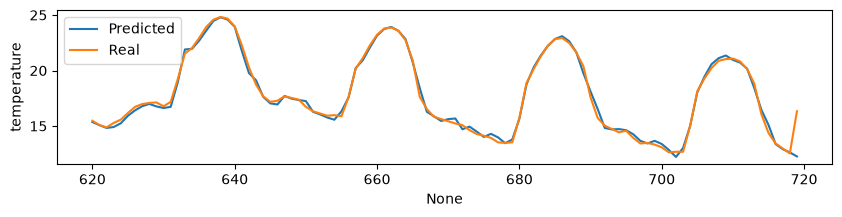

In [77]:
plt.figure(figsize=(10,2))
sns.lineplot(data=y_pred_val[len(y_pred_val)-100:], x=y_pred_val.index[len(y_pred_val)-100:], y='temperature', label='Predicted')
sns.lineplot(data=y_val[len(y_pred_val)-100:], x=y_val.index[len(y_pred_val)-100:], y='temperature', label='Real')

<Axes: xlabel='None', ylabel='humidity'>

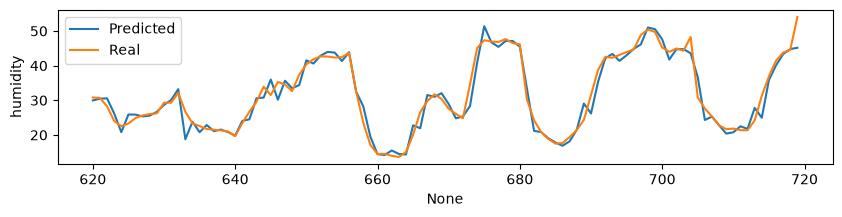

In [78]:
plt.figure(figsize=(10,2))
sns.lineplot(data=y_pred_val[len(y_pred_val)-100:], x=y_pred_val.index[len(y_pred_val)-100:], y='humidity', label='Predicted')
sns.lineplot(data=y_val[len(y_pred_val)-100:], x=y_val.index[len(y_pred_val)-100:], y='humidity', label='Real')

<Axes: xlabel='None', ylabel='pressure'>

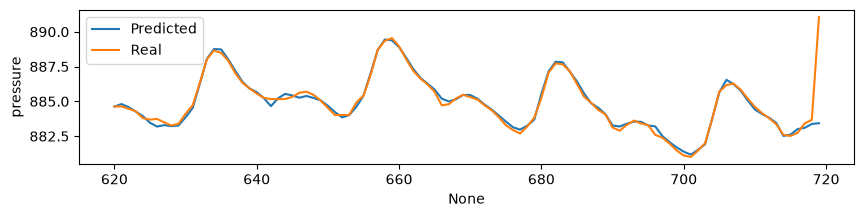

In [79]:
plt.figure(figsize=(10,2))
sns.lineplot(data=y_pred_val[len(y_pred_val)-100:], x=y_pred_val.index[len(y_pred_val)-100:], y='pressure', label='Predicted')
sns.lineplot(data=y_val[len(y_pred_val)-100:], x=y_val.index[len(y_pred_val)-100:], y='pressure', label='Real')

<Axes: xlabel='None', ylabel='temperature'>

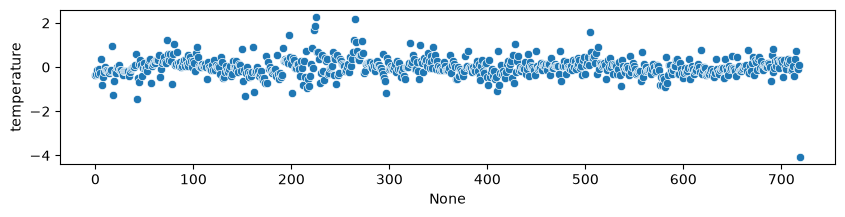

In [80]:
plt.figure(figsize=(10,2))
sns.scatterplot(data=(y_pred_val-y_val), x=y_val.index, y='temperature')

<Axes: xlabel='None', ylabel='humidity'>

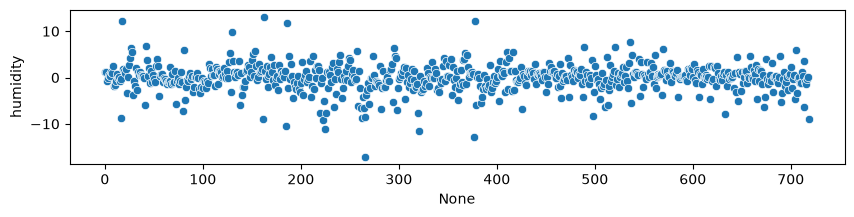

In [83]:
plt.figure(figsize=(10,2))
sns.scatterplot(data=(y_pred_val-y_val), x=y_val.index, y='humidity')

<Axes: xlabel='None', ylabel='pressure'>

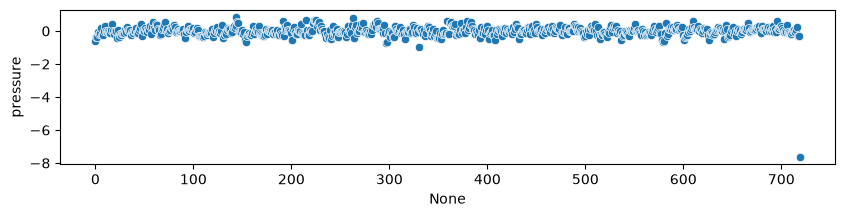

In [84]:
plt.figure(figsize=(10,2))
sns.scatterplot(data=(y_pred_val-y_val), x=y_val.index, y='pressure')

In [81]:
from sklearn.metrics import r2_score

In [82]:
temp_score = r2_score(y_pred=y_pred_val['temperature'], y_true=y_val['temperature'])
humidity_score = r2_score(y_pred=y_pred_val['humidity'], y_true=y_val['humidity'])
press_score = r2_score(y_pred=y_pred_val['pressure'], y_true=y_val['pressure'])
temp_score, humidity_score, press_score

(0.9907833885360126, 0.9673066043058636, 0.9678130720069065)

In [85]:
import json
best_hps_dict = best_hps.values
with open("/home/Beta/Desktop/coding/weather_anamoly/artifacts/lstm_forecast_best_hps.json", "w") as f:
    json.dump(best_hps_dict, f, indent=4)